# Curve-shape diagnostics and apparent exponents

The flow index $n$ is the parameter of the Herschel–Bulkley (HB) law that is most often read as a fingerprint of the material: $n\approx0.5$ for soft glasses, $n=1$ for a Bingham plastic, $n>1$ for a shear-thickening concrete. Yet the number that comes out of a fit depends on things that have nothing to do with the microstructure — the range of shear rates, a solvent contribution that grows with rate, the geometry in which the stress was measured, or an intercept subtracted before taking a logarithm. This notebook assembles the tools the review offers for telling an intrinsic exponent from an apparent one. The centrepiece is the **three-rate diagnostic** of Supplementary Note S8: measure the stress at three geometrically spaced rates and the ratio of the two stress increments gives $r^n$, with the unknown yield stress cancelling exactly. We derive it, test it on exact and on noisy synthetic data, apply it to the 1926 capillary data of Herschel and Bulkley, and use it to expose the two other sources of apparent exponents treated in the review: the solvent crossover of Fig. 9(b) and the geometry-dependent onset exponents of Fig. 9(a) and Table SIV. A short last section shows what a change of fitting window did to the flow index of a drilling fluid.

Notebook 01 (`01_herschel_bulkley_1926.ipynb`) converts the 1926 data into wall variables and fits them; notebook 03 treats least-squares fitting and identifiability; notebook 05 derives the pipe-flow solution and its near-onset exponent. We reuse their formulas here and keep those parts short.

## Where this is in the review

* **Supplementary Note S8** *A three-rate diagnostic for curve shape* — the stress increments, **Eqs. (S18)–(S19)**; the exponent estimate, **Eq. (S20)**; the reconstruction of $K$ and $\sigma_y$, **Eq. (S21)**; the worked example $\sigma=10+5\dot\gamma^{1/2}$; the variance of the increments, **Eq. (S22)**, and of the exponent, **Eq. (S23)**. Script `scripts/verify_transfer_diagnostic.py`.
* **Sec. V C** *Predicted and fitted exponents* — the plastic-plus-solvent law, **Eq. (13)**, its local excess-stress slope, **Eq. (14)**, and the effect of an incorrect intercept; Caggioni, Trappe and Spicer (2020). **Fig. 9(b)** (`scripts/fig09_transport_exponents.py`).
* **Sec. VII C** *Transport exponents near onset* — the pipe flow rate in excess-stress form, **Eq. (23)**, the near-onset asymptote, **Eq. (24)**, and the far-field one, **Eq. (25)**; **Fig. 9(a)**. **Supplementary Note S7 A** — the Couette counterpart, **Eqs. (S15)–(S16)**, the channel flow rate, **Eq. (S17)**, and **Table SIV** (near-onset exponents of the common geometries).
* **Sec. III B** and **Fig. 3** — the drilling fluid whose index changed from 0.98 to 0.83 with the fitting window (Saasen and Ytrehus, 2020); **Sec. VI D** — the same fluid's consistencies, 0.023 against 0.055 Pa s$^n$, and the ill-conditioning of HB fits (Mullineux, 2008). Data `data/hb_parameter_atlas.csv`, `data/figure_data/fig03_parameter_atlas.csv`.
* **Sec. II** and **Fig. 1** — the 1926 capillary data (`data/hb1926_table3.csv`, `data/hb1926_reanalysis.json`); **Sec. IV C**, Eq. (9) — the local index $n'$ of a wall flow curve.

## Learning objectives

1. Derive the three-rate identity $\Delta_2/\Delta_1=r^n$, use it to estimate $n$, $K$ and $\sigma_y$ from three stresses, and explain why a constant stress offset cannot affect the exponent.
2. Propagate independent stress errors through the diagnostic, Eqs. (S22)–(S23), and explain why the two increments are anticorrelated and why the diagnostic fails near a plateau.
3. Recognize three sources of apparent exponents that have nothing to do with the material: a solvent crossover (Eq. (14)), the geometry of the flow (Table SIV), and the fitting window or a wrong intercept.
4. Reproduce Fig. 9 and the near-onset exponents of Table SIV numerically.
5. Apply the diagnostic to real data (the 1926 capillary measurements) and read its spread as a measure of information, not as a parameter estimate.

## 1. Theory

### 1.1 The three-rate identity (Note S8)

Take steady shear rates $g$, $rg$ and $r^2g$ with $g>0$, $r>1$, and let $s_0$, $s_1$, $s_2$ be the measured stresses, corrected for the apparatus and boundary effects of the experiment. If one HB branch with constant parameters holds,

$$
\Delta_1=s_1-s_0=Kg^n(r^n-1),\qquad \Delta_2=s_2-s_1=Kg^nr^n(r^n-1), \tag{S18, S19}
$$

so that

$$
\frac{\Delta_2}{\Delta_1}=r^n,\qquad n_{\rm tri}=\frac{\ln(\Delta_2/\Delta_1)}{\ln r}. \tag{S20}
$$

The yield intercept cancels: a constant stress offset, whether a true yield stress or a torque-calibration error, leaves $n_{\rm tri}$ unchanged. Once $n_{\rm tri}$ is known,

$$
K_{\rm tri}=\frac{\Delta_1}{g^{n_{\rm tri}}(r^{n_{\rm tri}}-1)},\qquad \sigma_{y,\rm tri}=s_0-\frac{\Delta_1}{r^{n_{\rm tri}}-1}. \tag{S21}
$$

*Worked example of Note S8:* $\sigma=10+5\dot\gamma^{1/2}$ at $1$, $4$ and $16$ s$^{-1}$ gives $15$, $20$ and $30$ Pa; $\Delta_2/\Delta_1=10/5=2=4^{1/2}$, so $n_{\rm tri}=1/2$. In exact data a sliding three-point window along a geometric rate sequence returns the same exponent everywhere; a *drift* of $n_{\rm tri}$ beyond its uncertainty rejects a single constant exponent over the tested interval — without, by itself, saying why.

### 1.2 Noise (Eqs. (S22)–(S23))

If the three stress errors are independent with common variance $\varsigma_s^2$, then $\mathrm{Var}(\Delta_1)=\mathrm{Var}(\Delta_2)=2\varsigma_s^2$ and $\mathrm{Cov}(\Delta_1,\Delta_2)=-\varsigma_s^2$: the shared middle stress makes the increments anticorrelated. First-order propagation through Eq. (S20) gives

$$
\mathrm{Var}(n_{\rm tri})\simeq\frac{2\varsigma_s^2}{(\ln r)^2}\left(\frac1{\Delta_1^2}+\frac1{\Delta_2^2}+\frac1{\Delta_1\Delta_2}\right), \tag{S23}
$$

where the positive cross term is the anticorrelation. Subtraction amplifies noise when the increments are small — near a stress plateau — and negative or unresolved increments invalidate the logarithm. For $n>0$ the admissible windows have $\Delta_2>\Delta_1>0$.

### 1.3 Apparent exponent I: a solvent crossover (Sec. V C)

A plastic power law plus a solvent term,

$$
\sigma=\sigma_y+A(\dot\gamma/\dot\gamma_*)^{n_0}+\eta_s\dot\gamma,\qquad 0<n_0<1, \tag{13}
$$

has the local logarithmic slope of the excess stress

$$
n_{\rm eff}=\frac{n_0A(\dot\gamma/\dot\gamma_*)^{n_0}+\eta_s\dot\gamma}{A(\dot\gamma/\dot\gamma_*)^{n_0}+\eta_s\dot\gamma}, \tag{14}
$$

which rises from $n_0$ to 1 as the solvent term grows (Fig. 9(b)). A three-parameter HB fit across the crossover has no reason to return $n_0$ (Caggioni et al., 2020, varied the solvent viscosity of emulsions through the temperature and saw the fitted exponent shift systematically). A second analysis effect: subtracting an incorrect intercept $\widehat{\sigma}_y$ from an exact HB curve gives the slope $nK\dot\gamma^n/(\sigma_y-\widehat{\sigma}_y+K\dot\gamma^n)$ — underestimating $\sigma_y$ depresses the low-rate slope. The three-rate diagnostic is immune to this second effect because it never subtracts an intercept.

### 1.4 Apparent exponent II: the geometry (Sec. VII C, Note S7)

In a pipe, with $\delta=\sigma_w-\sigma_y$, the exact flow rate is

$$
Q=\frac{\pi R^3}{K^{1/n}\sigma_w^3}\left[\frac{\delta^{3+1/n}}{3+1/n}+\frac{2\sigma_y\delta^{2+1/n}}{2+1/n}+\frac{\sigma_y^2\delta^{1+1/n}}{1+1/n}\right], \tag{23}
$$

so $Q\sim\pi R^3n\,\delta^{1+1/n}/[(n+1)K^{1/n}\sigma_y]$ near onset (Eq. (24)) and $Q\sim\pi R^3n(\sigma_w/K)^{1/n}/(3n+1)$ far above it (Eq. (25)). The extra power of $\delta$ comes from the vanishing width of the sheared annulus, not from the material. The same exponent $1+1/n$ governs a plane channel (Eq. (S17)) and a partly yielded Couette gap, where $\Omega=\frac{1}{2K^{1/n}}\int_{\max(\sigma_y,\sigma_o)}^{\sigma_i}\frac{(s-\sigma_y)^{1/n}}{s}\,\mathrm ds$ (Eq. (S15)) gives $\Omega\sim n\,\delta_i^{1+1/n}/[2(n+1)K^{1/n}\sigma_y]$ (Eq. (S16)); a plug sliding as a whole at a wall follows the exponent $p_s$ of the slip law instead (Table SIV).

### 1.5 Apparent exponent III: the fitting window (Secs. III B, VI D)

Because $(K,n)$ are strongly correlated in fits and the HB residual surface has a long valley (notebook 03), the same data fitted over different rate ranges can return visibly different indices. The review's example is a used drilling fluid: $n=0.98$, $K=0.023$ Pa s$^n$ over 0–1000 s$^{-1}$ but $n=0.83$, $K=0.055$ Pa s$^n$ over 0–300 s$^{-1}$ (Saasen and Ytrehus, 2020), a shift comparable to the difference between material classes in Fig. 3.

## 2. Setup

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the repository root whether the notebook runs from notebooks/ or from the root.
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if (ROOT.parent / "data").exists() and not (ROOT / "data").exists() else ROOT
DATA = ROOT / "data"
FIGDATA = DATA / "figure_data"
sys.path.insert(0, str(ROOT / "scripts"))
sys.dont_write_bytecode = True      # do not write __pycache__ files into scripts/

from hbstyle import C, hb_stress    # the article's palette and Eq. (3); hbstyle.save is never called
plt.rcParams["figure.dpi"] = 110
print("data folder found:", (ROOT / "data").is_dir())

from scipy.integrate import quad
from scipy.optimize import brentq, least_squares
import verify_transfer_diagnostic as vtd        # the review's own check of Note S8 (importing it runs nothing)
from verify_equations import pipe_q, couette_omega   # Eq. (23) and the Couette integral of Eq. (21)

def figure_series(df, panel, series):
    '''x and y of one plotted series in a data/figure_data/<figure>.csv table.'''
    s = df[(df["panel"] == panel) & (df["series"] == series)].sort_values("index")
    if s.empty:
        raise KeyError(f"no series {series!r} in panel {panel!r}")
    return s["x"].to_numpy(float), s["y"].to_numpy(float)

data folder found: True


## 3. The three-rate diagnostic

### 3.1 The functions and the worked example

In [2]:
def triplet_exponent(s, r):
    '''n_tri of Eq. (S20) from three stresses s = (s0, s1, s2) at rates g, r g, r^2 g.'''
    d1, d2 = s[1] - s[0], s[2] - s[1]
    if not (d2 > d1 > 0):
        return np.nan                                   # unresolved or non-admissible window (Note S8)
    return np.log(d2 / d1) / np.log(r)

def triplet_parameters(g, r, s):
    '''(n_tri, K_tri, sigma_y,tri) of Eqs. (S20)-(S21) from the lowest rate g, the ratio r and the three stresses.'''
    n = triplet_exponent(s, r)
    d1 = s[1] - s[0]
    K = d1 / (g ** n * (r ** n - 1))
    sy = s[0] - d1 / (r ** n - 1)
    return n, K, sy

# the worked example of Note S8
g, r = 1.0, 4.0
rates = g * r ** np.arange(3)
s = hb_stress(rates, 10.0, 5.0, 0.5)
print("rates", rates, "1/s  ->  stresses", s, "Pa;  increments", np.diff(s), "Pa;  ratio", np.diff(s)[1] / np.diff(s)[0])
n_tri, K_tri, sy_tri = triplet_parameters(g, r, s)
print(f"n_tri = {n_tri:.6f}, K_tri = {K_tri:.6f} Pa s^n, sigma_y,tri = {sy_tri:.6f} Pa")
assert np.allclose(s, [15, 20, 30]) and np.allclose([n_tri, K_tri, sy_tri], [0.5, 5.0, 10.0])
assert np.isclose(vtd.exponent(s, r), n_tri)           # same value as the review's script

rates [ 1.  4. 16.] 1/s  ->  stresses [15. 20. 30.] Pa;  increments [ 5. 10.] Pa;  ratio 2.0
n_tri = 0.500000, K_tri = 5.000000 Pa s^n, sigma_y,tri = 10.000000 Pa


### 3.2 Exact reconstruction and invariance to an offset

Following `scripts/verify_transfer_diagnostic.py`, we reconstruct $(n,K,\sigma_y)$ for a grid of exponents, ratios and starting rates, and add a constant stress offset of 35 Pa (a miscalibrated torque, say): $n_{\rm tri}$ and $K_{\rm tri}$ must not change, and $\sigma_{y,\rm tri}$ must shift by exactly the offset.

In [3]:
cases = 0
for n in (0.2, 0.5, 1.0, 1.5):
    for r in (2.0, 4.0, 10.0):
        for g in (0.1, 1.0, 10.0):
            rates = g * r ** np.arange(3)
            s = hb_stress(rates, 10.0, 5.0, n)
            assert np.allclose(triplet_parameters(g, r, s), [n, 5.0, 10.0], rtol=1e-10)
            n_off, K_off, sy_off = triplet_parameters(g, r, s + 35.0)
            assert np.allclose([n_off, K_off, sy_off], [n, 5.0, 45.0], rtol=1e-10)
            cases += 1
print(f"{cases} cases: exact reconstruction of (n, K, sigma_y); with a 35 Pa offset, n and K unchanged and sigma_y,tri shifted by 35 Pa")
print("Consequence (Note S8): exponent consistency cannot establish absolute stress calibration.")

36 cases: exact reconstruction of (n, K, sigma_y); with a 35 Pa offset, n and K unchanged and sigma_y,tri shifted by 35 Pa
Consequence (Note S8): exponent consistency cannot establish absolute stress calibration.


### 3.3 Sliding the window along exact HB data

With a geometric rate sequence of ratio $r$, every three consecutive points form a window. For exact HB data $n_{\rm tri}$ is the same in every window — our reference for what follows.

In [4]:
def sliding_triplets(rates, stresses, r):
    '''n_tri for every window of three consecutive points of a geometric rate sequence of ratio r;
    returns the geometric-centre rate of each window and the exponent.'''
    out = [(rates[i + 1], triplet_exponent(stresses[i:i + 3], r)) for i in range(len(rates) - 2)]
    return np.array(out).T

r = 2.0
rates = 1e-3 * r ** np.arange(0, 24)                       # 1e-3 to about 8e3 1/s
for n in (0.3, 0.5, 1.0):
    _, ntri = sliding_triplets(rates, hb_stress(rates, 10.0, 5.0, n), r)
    assert np.allclose(ntri, n, rtol=1e-10)
print("(i) exact HB data: n_tri is constant in every window, equal to n, for n = 0.3, 0.5 and 1")

(i) exact HB data: n_tri is constant in every window, equal to n, for n = 0.3, 0.5 and 1


## 4. Apparent exponent I: the solvent crossover

### 4.1 $n_{\rm tri}$ along a plastic-plus-solvent curve, and Fig. 9(b)

We generate data from Eq. (13) with $\sigma_y=10$ Pa, $A=5$ Pa, $\dot\gamma_*=1$ s$^{-1}$, $n_0=0.5$ and $\eta_s\dot\gamma_*/A=0.01$, $0.1$ and $1$, slide the three-rate window along each curve, and compare with the local slope $n_{\rm eff}$ of Eq. (14). The three $n_{\rm eff}$ curves are those of Fig. 9(b), which we check against `data/figure_data/fig09_transport_exponents.csv`.

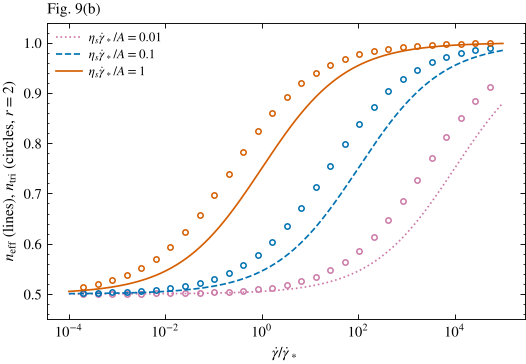

Fig. 9(b): the three n_eff curves agree with data/figure_data/fig09_transport_exponents.csv (rtol 1e-8);
(ii) HB + solvent: n_tri drifts from n0 = 0.5 toward 1 along each curve, following Eq. (14) to within 0.09.


In [5]:
def stress_eq13(gd, sy, A, gstar, n0, eta_s):
    return sy + A * (gd / gstar) ** n0 + eta_s * gd

def neff_eq14(gd, A, gstar, n0, eta_s):
    x = gd / gstar
    return (n0 * A * x ** n0 + eta_s * gstar * x) / (A * x ** n0 + eta_s * gstar * x)

fd9 = pd.read_csv(FIGDATA / "fig09_transport_exponents.csv", comment="#")
sy, A, gstar, n0 = 10.0, 5.0, 1.0, 0.5
x = np.logspace(-4, 5, 600)                                  # gdot / gdot_* grid of the figure script
r = 2.0
rates = gstar * 1e-4 * r ** np.arange(0, 31)                 # 1e-4 to about 1e5 1/s
fig, ax = plt.subplots(figsize=(5.6, 3.5))
for v, col, ls in zip([0.01, 0.1, 1.0], [C["purple"], C["blue"], C["red"]], [":", "--", "-"]):
    eta_s = v * A / gstar
    ne = neff_eq14(x * gstar, A, gstar, n0, eta_s)
    ax.semilogx(x, ne, color=col, ls=ls, label=rf"$\eta_s\dot\gamma_*/A={v:g}$")
    gc, ntri = sliding_triplets(rates, stress_eq13(rates, sy, A, gstar, n0, eta_s), r)
    ax.semilogx(gc / gstar, ntri, "o", color=col, ms=3.5, mfc="none")
    xs, ys = figure_series(fd9, "(b)", rf"$\eta_s\dot\gamma_*/A={v:g}$")
    assert np.allclose(xs, x, rtol=1e-8) and np.allclose(ys, ne, rtol=1e-8)
    # the three-rate estimate tracks n_eff: within 0.09 everywhere for r = 2 (a window spans a factor r^2 = 4 in rate)
    assert np.nanmax(np.abs(ntri - neff_eq14(gc, A, gstar, n0, eta_s))) < 0.1
ax.set(xlabel=r"$\dot\gamma/\dot\gamma_*$", ylabel=r"$n_{\rm eff}$ (lines), $n_{\rm tri}$ (circles, $r=2$)", ylim=(0.45, 1.04))
ax.set_title("Fig. 9(b)", loc="left", fontsize=10)
ax.legend(loc="upper left", fontsize=8.5); plt.show()
print("Fig. 9(b): the three n_eff curves agree with data/figure_data/fig09_transport_exponents.csv (rtol 1e-8);")
print("(ii) HB + solvent: n_tri drifts from n0 = 0.5 toward 1 along each curve, following Eq. (14) to within 0.09.")

The three-rate estimate follows the local slope through the crossover, running slightly ahead of it (by up to 0.09) because a window of ratio $r=2$ spans a factor of four in rate and $n_{\rm tri}$ is a secant over it, not a local derivative. The drift of $n_{\rm tri}$ is the lack-of-fit signal Note S8 describes: a constant exponent is rejected over the window, though the diagnostic does not say that a solvent is the cause. What does a three-parameter HB fit return across the crossover? We fit $(\sigma_y, K, n)$ by least squares in $\ln\sigma$ over three decade-wide windows of the $\eta_s\dot\gamma_*/A=0.1$ curve.

In [6]:
eta_s = 0.1 * A / gstar
def hb_fit(gd, s):
    '''Least-squares HB fit with log residuals; parameters (sigma_y, ln K, n).'''
    res = lambda p: np.log(p[0] + np.exp(p[1]) * gd ** p[2]) - np.log(s)
    sol = least_squares(res, [s.min() * 0.9, np.log(1.0), 0.7], bounds=([0, -20, 0.05], [s.min(), 10, 3]))
    return sol.x[0], np.exp(sol.x[1]), sol.x[2], np.sqrt(np.mean(sol.fun ** 2))

print("window (1/s)     sigma_y (Pa)   K (Pa s^n)    n      rms log residual    n_eff at window centre")
for lo, hi in [(1e-2, 1e0), (1e0, 1e2), (1e2, 1e4)]:
    gd = np.logspace(np.log10(lo), np.log10(hi), 25)
    s = stress_eq13(gd, sy, A, gstar, n0, eta_s)
    sy_f, K_f, n_f, rms = hb_fit(gd, s)
    print(f"{lo:7.0e}-{hi:5.0e}     {sy_f:8.3f}      {K_f:8.3f}   {n_f:6.3f}      {rms:.1e}             {neff_eq14(np.sqrt(lo * hi), A, gstar, n0, eta_s):.3f}")

window (1/s)     sigma_y (Pa)   K (Pa s^n)    n      rms log residual    n_eff at window centre
  1e-02-1e+00       10.059         5.426    0.539      4.1e-04             0.515
  1e+00-1e+02       12.092         3.624    0.712      7.5e-03             0.620
  1e+02-1e+04       37.195         1.031    0.930      7.7e-03             0.880


Each window is fitted almost perfectly (residuals below 1 %), with an index anywhere between the plastic value 0.5 and the solvent value 1 and an intercept that drifts with it. None of these fits is "wrong" as a description of its window; none of them measures $n_0$. This is the sense in which Sec. V C says a fitted exponent is window-dependent even when the microscopic law is known.

### 4.2 The intercept effect, and why the diagnostic is immune to it

Sec. V C also warns that subtracting an incorrect intercept $\widehat{\sigma}_y$ from an exact HB curve gives the slope $nK\dot\gamma^n/(\sigma_y-\widehat{\sigma}_y+K\dot\gamma^n)$. We check that formula numerically and show that $n_{\rm tri}$ on the same data stays at $n$.

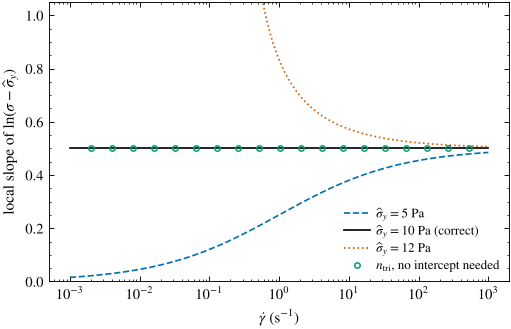

slope of ln(sigma - sigma_y_hat) agrees with n K gd^n / (sigma_y - sigma_y_hat + K gd^n); n_tri = n in every window


In [7]:
sy, K, n = 10.0, 5.0, 0.5
gd = np.logspace(-3, 3, 400)
s = hb_stress(gd, sy, K, n)
fig, ax = plt.subplots(figsize=(5.4, 3.3))
for scy, col, ls in [(5.0, C["blue"], "--"), (10.0, C["black"], "-"), (12.0, C["red"], ":")]:
    excess = s - scy
    ok = excess > 0
    slope = np.gradient(np.log(excess[ok]), np.log(gd[ok]))
    formula = n * K * gd[ok] ** n / (sy - scy + K * gd[ok] ** n)
    smooth = (excess[ok] > 1.0)[5:-5]                      # away from the singular point of ln(sigma - sigma_y_hat)
    assert np.allclose(slope[5:-5][smooth], formula[5:-5][smooth], rtol=1e-2, atol=1e-3)
    ax.semilogx(gd[ok], slope, color=col, ls=ls, label=rf"$\widehat{{\sigma}}_y={scy:g}$ Pa" + (" (correct)" if scy == sy else ""))
gc, ntri = sliding_triplets(1e-3 * 2.0 ** np.arange(0, 21), hb_stress(1e-3 * 2.0 ** np.arange(0, 21), sy, K, n), 2.0)
ax.semilogx(gc, ntri, "o", color=C["green"], ms=3.5, mfc="none", label=r"$n_{\rm tri}$, no intercept needed")
ax.set(xlabel=r"$\dot\gamma$ (s$^{-1}$)", ylabel=r"local slope of $\ln(\sigma-\widehat{\sigma}_y)$", ylim=(0, 1.05))
ax.legend(fontsize=8.5, loc="lower right"); plt.show()
print("slope of ln(sigma - sigma_y_hat) agrees with n K gd^n / (sigma_y - sigma_y_hat + K gd^n); n_tri = n in every window")

With the intercept underestimated ($\widehat{\sigma}_y=5$ Pa) the low-rate slope collapses toward zero; overestimated ($12$ Pa) the logarithm is undefined below about 0.2 s$^{-1}$ and the slope is inflated above it. The three-rate estimate never subtracts an intercept and returns $n=0.5$ throughout.

## 5. Noise: the propagated variance, Eqs. (S22)–(S23)

### 5.1 Monte Carlo check of the formula and the anticorrelation

We add independent Gaussian errors of standard deviation $\varsigma_s=0.1$ Pa to the three stresses of the worked example (15, 20, 30 Pa at $r=4$), repeat 20 000 times with a fixed seed, and compare the sample variance of $n_{\rm tri}$ with Eq. (S23) and with a finite-difference gradient (the check made by `scripts/verify_transfer_diagnostic.py`). We also check $\mathrm{Var}(\Delta_i)=2\varsigma_s^2$ and $\mathrm{Cov}(\Delta_1,\Delta_2)=-\varsigma_s^2$.

In [8]:
def var_ntri_S23(s, r, sigma_s):
    d1, d2 = s[1] - s[0], s[2] - s[1]
    return 2 * sigma_s ** 2 / np.log(r) ** 2 * (1 / d1 ** 2 + 1 / d2 ** 2 + 1 / (d1 * d2))

s0 = np.array([15.0, 20.0, 30.0]); r = 4.0; sig = 0.1
rng = np.random.default_rng(16)
noisy = s0 + rng.normal(0, sig, (20000, 3))
d = np.diff(noisy, axis=1)
n_mc = np.log(d[:, 1] / d[:, 0]) / np.log(r)
h = 1e-4
grad = np.array([(vtd.exponent(s0 + h * e, r) - vtd.exponent(s0 - h * e, r)) / (2 * h) for e in np.eye(3)])
var_fd = sig ** 2 * grad @ grad
print(f"Var(Delta_1), Var(Delta_2) = {d[:, 0].var():.5f}, {d[:, 1].var():.5f}  (2 sigma_s^2 = {2 * sig**2:.5f})")
print(f"Cov(Delta_1, Delta_2)      = {np.cov(d.T)[0, 1]:+.5f}  (-sigma_s^2 = {-sig**2:+.5f})")
print(f"std(n_tri): Monte Carlo {n_mc.std():.5f}, Eq. (S23) {np.sqrt(var_ntri_S23(s0, r, sig)):.5f}, finite-difference propagation {np.sqrt(var_fd):.5f}")
assert np.isclose(var_fd, var_ntri_S23(s0, r, sig), rtol=1e-6)
assert abs(n_mc.std() / np.sqrt(var_ntri_S23(s0, r, sig)) - 1) < 0.03 and abs(np.cov(d.T)[0, 1] / (-sig**2) - 1) < 0.05
print(f"mean n_tri = {n_mc.mean():.4f} (true 0.5): the first-order propagation is adequate here because both increments are well resolved")

Var(Delta_1), Var(Delta_2) = 0.02013, 0.01990  (2 sigma_s^2 = 0.02000)
Cov(Delta_1, Delta_2)      = -0.01016  (-sigma_s^2 = -0.01000)
std(n_tri): Monte Carlo 0.02711, Eq. (S23) 0.02699, finite-difference propagation 0.02699
mean n_tri = 0.5000 (true 0.5): the first-order propagation is adequate here because both increments are well resolved


### 5.2 Where the diagnostic breaks down: small increments

Eq. (S23) says the variance scales as $1/\Delta^2$. Near a stress plateau — low rates of a strongly shear-thinning material, where $K\dot\gamma^n\ll\sigma_y$ — the increments are tiny and the exponent becomes unusable, however good the stress resolution. We evaluate $\sqrt{\mathrm{Var}(n_{\rm tri})}$ along an HB curve for $\varsigma_s=0.1$ Pa and two window ratios.

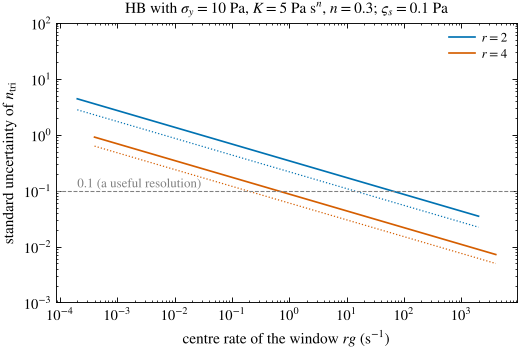

r = 2: n_tri resolved to 0.1 only for windows centred above about 60 1/s (Delta_1 = 3.21 Pa there)
r = 4: n_tri resolved to 0.1 only for windows centred above about 0.62 1/s (Delta_1 = 1.48 Pa there)


In [9]:
sy, K, n = 10.0, 5.0, 0.3
fig, ax = plt.subplots(figsize=(5.4, 3.3))
for r, col in [(2.0, C["blue"]), (4.0, C["red"])]:
    g = np.logspace(-4, 3, 200)
    sd = np.array([np.sqrt(var_ntri_S23(hb_stress(gg * r ** np.arange(3), sy, K, n), r, 0.1)) for gg in g])
    ax.loglog(g * r, sd, color=col, label=f"$r={r:g}$")
    # the increments: Delta_1 = K g^n (r^n - 1)
    ax.loglog(g * r, 0.1 / (K * g ** n * (r ** n - 1)) * np.sqrt(2) / np.log(r), color=col, ls=":", lw=0.8)
ax.axhline(0.1, color=C["grey"], lw=0.7, ls="--"); ax.text(2e-4, 0.115, "0.1 (a useful resolution)", fontsize=8.5, color=C["grey"])
ax.set(xlabel=r"centre rate of the window $rg$ (s$^{-1}$)", ylabel=r"standard uncertainty of $n_{\rm tri}$",
       title=rf"HB with $\sigma_y={sy:g}$ Pa, $K={K:g}$ Pa s$^n$, $n={n}$; $\varsigma_s=0.1$ Pa", ylim=(1e-3, 1e2))
ax.legend(fontsize=8.5, loc="upper right"); plt.show()
for r in (2.0, 4.0):
    g_ok = brentq(lambda gg: np.sqrt(var_ntri_S23(hb_stress(gg * r ** np.arange(3), sy, K, n), r, 0.1)) - 0.1, 1e-6, 1e4)
    print(f"r = {r:g}: n_tri resolved to 0.1 only for windows centred above about {r * g_ok:.2g} 1/s "
          f"(Delta_1 = {K * g_ok**n * (r**n - 1):.2f} Pa there)")

The dotted lines show the leading term, $\sqrt2\,\varsigma_s/(\Delta_1\ln r)$: the uncertainty is set by the size of the first increment relative to the stress noise. A wider window ($r=4$) helps because the increments are larger — but a wider window is also more likely to straddle a crossover (Sec. 4), which is the trade-off of any local estimate. Note S8 adds that adjacent triplets share observations and are not independent estimates, and that correlated instrument errors, rate uncertainty and heteroscedasticity require the full measurement covariance.

### 5.3 Noisy synthetic data with the propagated variance

Finally a complete synthetic experiment (iv): an HB curve sampled at $r=2$ with $\varsigma_s=0.1$ Pa, the sliding diagnostic with its error bars from Eq. (S23), and the windows that fail the admissibility condition $\Delta_2>\Delta_1>0$. The cell also prints an inverse-variance weighted mean of the resolved windows for orientation only: adjacent windows are correlated, and it excludes the rejected and unresolved windows, which Note S8 warns biases the result; it is not an estimator.

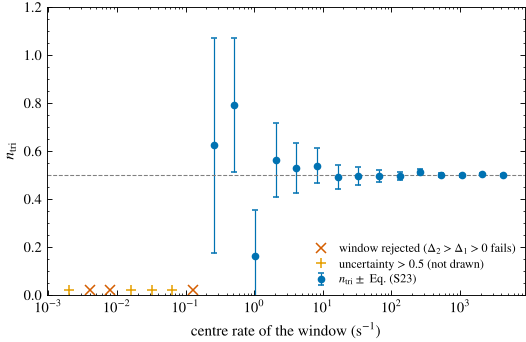

3 of 22 windows rejected, 4 unresolved; inverse-variance weighted mean of the rest = 0.500 (true 0.5)
(the weighted mean is only indicative: adjacent windows share two of their three stresses and are correlated,
 and it excludes the rejected and unresolved windows, which Note S8 warns biases the result; it is not an estimator)


In [10]:
sy, K, n, r = 10.0, 5.0, 0.5, 2.0
rates = 1e-3 * r ** np.arange(0, 24)
rng = np.random.default_rng(1926)
s_noisy = hb_stress(rates, sy, K, n) + rng.normal(0, 0.1, rates.size)
gc, ntri = sliding_triplets(rates, s_noisy, r)
sd = np.array([np.sqrt(var_ntri_S23(s_noisy[i:i + 3], r, 0.1)) if np.isfinite(ntri[i]) else np.nan for i in range(len(ntri))])
ok = np.isfinite(ntri) & (sd < 0.5)
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.errorbar(gc[ok], ntri[ok], yerr=sd[ok], fmt="o", color=C["blue"], ms=4, capsize=2, lw=0.8, label=r"$n_{\rm tri}\pm$ Eq. (S23)")
bad = ~np.isfinite(ntri)
ax.plot(gc[bad], np.full(bad.sum(), 0.02), "x", color=C["red"], ms=6, label=r"window rejected ($\Delta_2>\Delta_1>0$ fails)")
ax.plot(gc[~ok & ~bad], np.full((~ok & ~bad).sum(), 0.02), "+", color=C["orange"], ms=7, label="uncertainty > 0.5 (not drawn)")
ax.axhline(n, color=C["grey"], lw=0.7, ls="--")
ax.set(xscale="log", xlabel=r"centre rate of the window (s$^{-1}$)", ylabel=r"$n_{\rm tri}$", ylim=(0, 1.2))
ax.legend(fontsize=8, loc="lower right"); plt.show()
w = 1 / sd[ok] ** 2
n_w = np.sum(w * ntri[ok]) / np.sum(w)
print(f"{bad.sum()} of {len(ntri)} windows rejected, {(~ok & ~bad).sum()} unresolved; inverse-variance weighted mean of the rest = {n_w:.3f} (true {n})")
print("(the weighted mean is only indicative: adjacent windows share two of their three stresses and are correlated,")
print(" and it excludes the rejected and unresolved windows, which Note S8 warns biases the result; it is not an estimator)")

## 6. The 1926 capillary data

The rubber solutions of Herschel and Bulkley (1926) are the subject of notebook 01, which converts the printed pressures and flow rates into wall shear stress $\sigma_w=Pd/(4L)$ and apparent wall shear rate $32q/(\pi d^3)$, applies the Weissenberg–Rabinowitsch–Mooney correction $\dot\gamma_w=\dot\gamma_{\rm app}(3n'+1)/(4n')$ with $n'$ from a quadratic fit of $\ln\sigma_w$ against $\ln\dot\gamma_{\rm app}$, and fits the pooled series of each concentration (results stored in `data/hb1926_reanalysis.json`: $n=0.81$, 0.74 and 0.68, $\sigma_y=0$). We repeat the conversion in one cell and then apply the diagnostic.

The measured rates are not geometrically spaced. **Beyond the article**, we therefore use the general form of the identity for three arbitrary rates $g_0<g_1<g_2$,

$$
\frac{\Delta_2}{\Delta_1}=\frac{g_2^n-g_1^n}{g_1^n-g_0^n},
$$

which reduces to $r^n$ for $g_k=r^kg$ and is solved for $n$ by bracketing. We take every triplet of points within a series whose rate ratios are both at least 1.5, so that the increments are resolved.

In [11]:
t3 = pd.read_csv(DATA / "hb1926_table3.csv")
DIM = {"B3": (0.1018, 10.0), "B2": (0.0689, 14.6)}            # capillary (d, L) in cm, as in notebook 01
GF_PER_CM2 = 1e-3 * 9.80665 / 1e-4                             # Pa per gf/cm^2
d_cm = t3.instrument.map(lambda k: DIM[k][0]); L_cm = t3.instrument.map(lambda k: DIM[k][1])
t3["sigma_w_Pa"] = t3.P_g_per_cm2 * GF_PER_CM2 * d_cm / (4 * L_cm)
t3["gdot_app"] = 32 * t3.q_cm3_per_s / (np.pi * d_cm ** 3)

def wrm(series):
    x, y = np.log(series.gdot_app.values), np.log(series.sigma_w_Pa.values)
    c = np.polyfit(x, y, 2); nprime = 2 * c[0] * x + c[1]
    return series.gdot_app.values * (3 * nprime + 1) / (4 * nprime)

parts = []
for key, s_ in t3.groupby(["instrument", "conc_pct"]):
    s_ = s_.sort_values("P_g_per_cm2").copy(); s_["gdot_w"] = wrm(s_); parts.append(s_)
w = pd.concat(parts, ignore_index=True)

def triplet_general(g, s):
    '''n from three stresses at arbitrary rates (the identity generalized; reduces to Eq. (S20) for geometric spacing).'''
    d1, d2 = s[1] - s[0], s[2] - s[1]
    if not (d1 > 0 and d2 > 0):
        return np.nan, np.nan, np.nan
    f = lambda n: d2 / d1 - (g[2] ** n - g[1] ** n) / (g[1] ** n - g[0] ** n)
    try:
        n = brentq(f, 0.05, 3.0)
    except ValueError:
        return np.nan, np.nan, np.nan
    K = d1 / (g[1] ** n - g[0] ** n)
    return n, K, s[0] - K * g[0] ** n

# sanity check of the generalization on exact geometric data: must equal Eq. (S20)
g_chk = 1.0 * 4.0 ** np.arange(3)
assert np.allclose(triplet_general(g_chk, hb_stress(g_chk, 10, 5, 0.5)), [0.5, 5.0, 10.0])

PAIRS = [(("B3", 0.693), ("B2", 0.692)), (("B3", 0.993), ("B2", 1.004)), (("B3", 1.21), ("B2", 1.19))]
stored = json.loads((DATA / "hb1926_reanalysis.json").read_text())["pooled_fits"]
rows = []
for pair, fit in zip(PAIRS, stored):
    for inst, conc in pair:
        s_ = w[(w.instrument == inst) & np.isclose(w.conc_pct, conc)]
        g, sw = s_.gdot_w.values, s_.sigma_w_Pa.values
        for i in range(len(g)):
            for j in range(i + 1, len(g)):
                for k in range(j + 1, len(g)):
                    if g[j] / g[i] >= 1.5 and g[k] / g[j] >= 1.5:
                        n_, K_, sy_ = triplet_general(g[[i, j, k]], sw[[i, j, k]])
                        rows.append({"pair": f"{pair[0][1]:.3f}% / {pair[1][1]:.3f}%", "instrument": inst, "n_tri": n_,
                                     "K_tri": K_, "sigma_y_tri": sy_, "n_pooled_fit": fit["n"]})
tri = pd.DataFrame(rows).dropna()
summary = tri.groupby("pair").agg(triplets=("n_tri", "size"), n_tri_median=("n_tri", "median"), n_tri_std=("n_tri", "std"),
                                  n_pooled_fit=("n_pooled_fit", "first"), sigma_y_tri_median=("sigma_y_tri", "median"),
                                  sigma_y_tri_std=("sigma_y_tri", "std"))
print(summary.round(3).to_string())
assert (np.abs(summary.n_tri_median - summary.n_pooled_fit) < 0.06).all()
assert (np.abs(summary.sigma_y_tri_median) < 3.0).all()

                 triplets  n_tri_median  n_tri_std  n_pooled_fit  sigma_y_tri_median  sigma_y_tri_std
pair                                                                                                 
0.693% / 0.692%       132         0.819      0.045         0.809               0.072            0.709
0.993% / 1.004%        77         0.718      0.061         0.739              -0.784            2.589
1.210% / 1.190%        46         0.633      0.047         0.677              -2.547            3.349


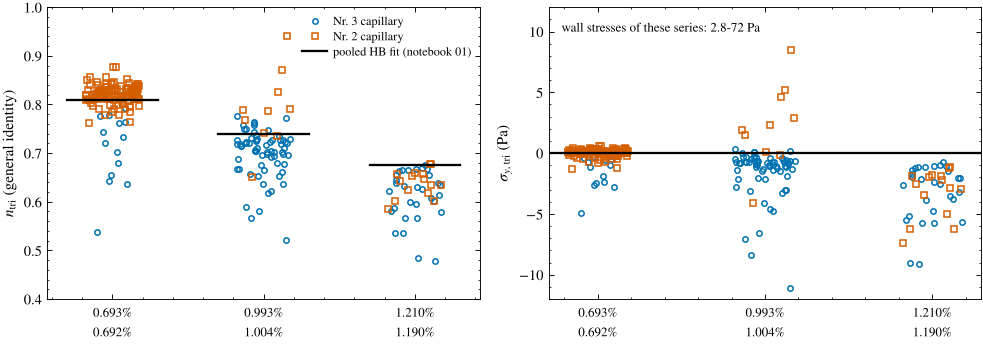

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.4))
for i, (pair, grp) in enumerate(tri.groupby("pair")):
    jitter = rng.uniform(-0.18, 0.18, len(grp))
    for inst, mk in [("B3", "o"), ("B2", "s")]:
        m = grp.instrument == inst
        ax1.plot(i + jitter[m], grp.n_tri[m], mk, ms=3.5, mfc="none", color=C["blue"] if inst == "B3" else C["red"],
                 label=f"{'Nr. 3' if inst == 'B3' else 'Nr. 2'} capillary" if i == 0 else None)
        ax2.plot(i + jitter[m], grp.sigma_y_tri[m], mk, ms=3.5, mfc="none", color=C["blue"] if inst == "B3" else C["red"])
    ax1.plot([i - 0.3, i + 0.3], [grp.n_pooled_fit.iloc[0]] * 2, color=C["black"], lw=1.5, label="pooled HB fit (notebook 01)" if i == 0 else None)
ax2.axhline(0, color=C["black"], lw=1.5)
for ax in (ax1, ax2):
    ax.set_xticks(range(3)); ax.set_xticklabels([p.replace(" / ", "\n") for p in summary.index], fontsize=8.5)
ax1.set(ylabel=r"$n_{\rm tri}$ (general identity)", ylim=(0.4, 1.0)); ax1.legend(fontsize=8, loc="upper right")
ax2.set(ylabel=r"$\sigma_{y,{\rm tri}}$ (Pa)", ylim=(-12, 12))
used = w[[any(i == a and np.isclose(c, b) for a, b in sum(map(list, PAIRS), [])) for i, c in zip(w.instrument, w.conc_pct)]]
ax2.text(0.03, 0.95, f"wall stresses of these series: {used.sigma_w_Pa.min():.1f}-{used.sigma_w_Pa.max():.0f} Pa", transform=ax2.transAxes, va="top", fontsize=8.5)
fig.tight_layout(); plt.show()

The medians of $n_{\rm tri}$ (0.82, 0.72, 0.63) sit close to the pooled HB fits (0.81, 0.74, 0.68) and fall with concentration, and the reconstructed yield stresses scatter around zero with a spread of a few pascals against wall stresses of 3–72 Pa — slightly negative for the more concentrated pairs (medians $-0.8$ and $-2.5$ Pa), the same tendency as the unconstrained fits of notebook 01 ($-0.2$, $-1.2$ and $-7.6$ Pa) and the opposite sign from a yield stress. The diagnostic is thus *compatible* with a single power law without yield stress over each series, which is the conclusion of Sec. II C. It does not prove it — Note S8 is explicit that a constant triplet exponent establishes compatibility with the curve shape, not a true threshold — and the spread of several hundredths in $n$ from triplets that share points is a reminder of how much a derivative of data costs. Notebook 01 reaches the same conclusion by profiling the residual against a fixed yield stress.

## 7. Apparent exponent II: the geometry

### 7.1 Fig. 9(a): the exponent crossover of the pipe solution

We compute $Q$ from Eq. (23) at $n=0.5$ with `pipe_q` (the review's implementation), take the logarithmic slope exactly as the figure script does, and check against the figure data. Notebook 05 discusses this figure at length; here it is the geometric counterpart of Fig. 9(b).

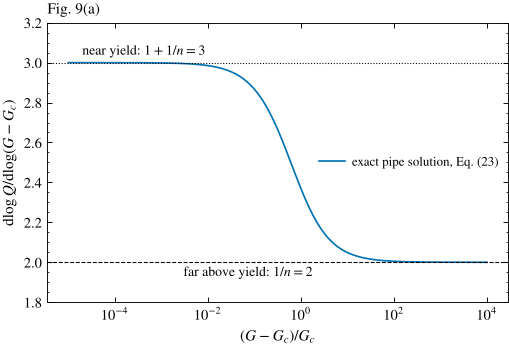

Fig. 9(a): slope curve and both limits agree with data/figure_data/fig09_transport_exponents.csv (rtol 1e-8).


In [13]:
n = 0.5
e = np.logspace(-5, 4, 700)                                   # (G - Gc)/Gc = delta/sigma_y
q = np.array([pipe_q(1 + xx, 1.0, 1.0, n) for xx in e])
slope = np.gradient(np.log(q), np.log(e))
xs, ys = figure_series(fd9, "(a)", "exact pipe solution")
assert np.allclose(xs, e, rtol=1e-8) and np.allclose(ys, slope, rtol=1e-8)
hl = fd9[(fd9.panel == "(a)") & (fd9.kind == "hline")].set_index("series").y
assert np.isclose(hl["near-yield limit 1+1/n"], 1 + 1 / n) and np.isclose(hl["far-from-yield limit 1/n"], 1 / n)

fig, ax = plt.subplots(figsize=(5.4, 3.3))
ax.semilogx(e, slope, color=C["blue"], label="exact pipe solution, Eq. (23)")
ax.axhline(1 + 1 / n, color="k", ls=":", lw=0.7); ax.axhline(1 / n, color="k", ls="--", lw=0.7)
ax.text(2e-5, 3.02, r"near yield: $1+1/n=3$", fontsize=9, va="bottom"); ax.text(3e-3, 1.98, r"far above yield: $1/n=2$", fontsize=9, va="top")
ax.set(xlabel=r"$(G-G_c)/G_c$", ylabel=r"$\mathrm{d}\log Q/\mathrm{d}\log(G-G_c)$", ylim=(1.8, 3.2))
ax.set_title("Fig. 9(a)", loc="left", fontsize=10); ax.legend(fontsize=8.5, loc="center right"); plt.show()
print("Fig. 9(a): slope curve and both limits agree with data/figure_data/fig09_transport_exponents.csv (rtol 1e-8).")

### 7.2 Table SIV: the near-onset exponent of each geometry

For each geometry of Table SIV we evaluate the response at two small excess stresses and read off the exponent from their ratio. The channel uses Eq. (S17); the Couette cell uses Eq. (S15), which we also cross-check against the radial integral `couette_omega` of `scripts/verify_equations.py`; the sliding plug uses the slip law of Eq. (27), $u_s=B_s(\sigma_w-\sigma_s)_+^{p_s}$, with $\sigma_s<\sigma_y$, so that the whole plug moves before the bulk yields and $Q=\pi R^2u_s$.

In [14]:
sy, K = 1.0, 1.0

def channel_q_S17(delta, ty, K, n, H=1.0):
    tw = ty + delta
    return 2 * H ** 2 / (K ** (1 / n) * tw ** 2) * (delta ** (2 + 1 / n) / (2 + 1 / n) + ty * delta ** (1 + 1 / n) / (1 + 1 / n))

def couette_omega_S15(sigma_i, ty, K, n, Ri, Ro):
    '''Eq. (S15): inner angular velocity, stationary outer cylinder, from the integral in the stress variable.'''
    sigma_o = sigma_i * (Ri / Ro) ** 2
    if sigma_i <= ty:
        return 0.0
    lo = max(ty, sigma_o)
    return quad(lambda s_: (s_ - ty) ** (1 / n) / s_, lo, sigma_i, epsabs=0, epsrel=1e-12)[0] / (2 * K ** (1 / n))

Ri, Ro = 1.0, 1.5
# cross-check (S15) against the radial form of Eq. (21) coded in scripts/verify_equations.py
for n_ in (0.5, 1.0):
    for sigma_i in (1.5, 3.0):
        T = 2 * np.pi * Ri ** 2 * sigma_i                      # torque per unit length
        assert np.isclose(couette_omega_S15(sigma_i, sy, K, n_, Ri, Ro), couette_omega(T, sy, K, n_, Ri, Ro), rtol=1e-8)

def local_exponent(f, d1=1e-6, d2=2e-6):
    return np.log(f(d2) / f(d1)) / np.log(d2 / d1)

B_s, sigma_s, p_s = 0.1, 0.5, 1.3                              # slip law of Eq. (27) for the sliding plug (illustrative)
rows = []
for n_ in (0.4, 0.7, 1.0):
    rows.append({"n": n_,
                 "homogeneous shear, gdot ~ (sigma - sigma_y)^1/n": local_exponent(lambda d: (d / K) ** (1 / n_)),
                 "pipe, Q ~ (sigma_w - sigma_y)^(1+1/n)": local_exponent(lambda d: pipe_q(sy + d, sy, K, n_)),
                 "channel, q ~ (sigma_w - sigma_y)^(1+1/n)": local_exponent(lambda d: channel_q_S17(d, sy, K, n_)),
                 "Couette, Omega ~ (sigma_i - sigma_y)^(1+1/n)": local_exponent(lambda d: couette_omega_S15(sy + d, sy, K, n_, Ri, Ro)),
                 "sliding plug, Q ~ (sigma_w - sigma_s)^p_s": local_exponent(lambda d: np.pi * B_s * d ** p_s),
                 "1/n": 1 / n_, "1 + 1/n": 1 + 1 / n_})
tab = pd.DataFrame(rows).set_index("n")
print(tab.round(4).T.to_string())
for n_, row in tab.iterrows():
    assert abs(row.iloc[0] - 1 / n_) < 1e-6 and all(abs(row.iloc[1:4] - (1 + 1 / n_)) < 2e-3) and abs(row.iloc[4] - p_s) < 1e-9
# Eq. (S16): the Couette prefactor near onset
for n_ in (0.4, 1.0):
    d = 1e-5
    assert np.isclose(couette_omega_S15(sy + d, sy, K, n_, Ri, Ro), n_ / (2 * (n_ + 1) * K ** (1 / n_) * sy) * d ** (1 + 1 / n_), rtol=1e-3)
print("\nTable SIV reproduced: 1/n in homogeneous shear; 1 + 1/n for pipe, channel and partly yielded Couette gap; p_s for a sliding plug.")
print("Eq. (S16) prefactor n/[2(n+1) K^(1/n) sigma_y] verified near onset.")

n                                                0.4     0.7  1.0
homogeneous shear, gdot ~ (sigma - sigma_y)^1/n  2.5  1.4286  1.0
pipe, Q ~ (sigma_w - sigma_y)^(1+1/n)            3.5  2.4286  2.0
channel, q ~ (sigma_w - sigma_y)^(1+1/n)         3.5  2.4286  2.0
Couette, Omega ~ (sigma_i - sigma_y)^(1+1/n)     3.5  2.4286  2.0
sliding plug, Q ~ (sigma_w - sigma_s)^p_s        1.3  1.3000  1.3
1/n                                              2.5  1.4286  1.0
1 + 1/n                                          3.5  2.4286  2.0

Table SIV reproduced: 1/n in homogeneous shear; 1 + 1/n for pipe, channel and partly yielded Couette gap; p_s for a sliding plug.
Eq. (S16) prefactor n/[2(n+1) K^(1/n) sigma_y] verified near onset.


A pressure–flow or torque–speed exponent measured near onset is therefore $1+1/n$, not $1/n$, in every geometry whose sheared layer vanishes at onset; and it is the exponent of the slip law when the plug slides. Fitting such data with the homogeneous-shear relation returns an index that is not the material's. (The thresholds must not be continued into the zero-yield limit: as Note S7 says, the topology of the active domain changes.)

### 7.3 Beyond the article: the three-rate diagnostic on a wall flow curve

If the diagnostic is applied to the *apparent* wall flow curve of a capillary — $\sigma_w$ against $\dot\gamma_{\rm app}=4Q/(\pi R^3)$ without the Weissenberg–Rabinowitsch–Mooney correction — it must drift, because the apparent curve of an HB fluid is not an HB curve. We generate it from Eq. (23) for $\sigma_y=10$ Pa, $K=5$ Pa s$^{0.5}$, $n=0.5$.

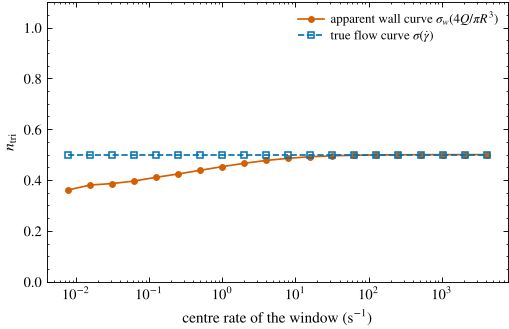

apparent curve: n_tri runs from 0.36 to 0.50 (material n = 0.5); true curve: constant 0.500


In [15]:
sy, K, n, R = 10.0, 5.0, 0.5, 1.0
sw = np.logspace(np.log10(10.2), np.log10(2000), 600)
gapp = np.array([4 * pipe_q(s_, sy, K, n, R) / (np.pi * R ** 3) for s_ in sw])
# resample the apparent curve on a geometric rate grid of ratio 2 (interpolation in log-log)
rates = 2.0 ** np.arange(-8, 14)
rates = rates[(rates > gapp.min()) & (rates < gapp.max())]
sw_app = np.exp(np.interp(np.log(rates), np.log(gapp), np.log(sw)))
gc, ntri_app = sliding_triplets(rates, sw_app, 2.0)
# the true wall flow curve on the same grid
gc_true, ntri_true = sliding_triplets(rates, hb_stress(rates, sy, K, n), 2.0)
fig, ax = plt.subplots(figsize=(5.4, 3.3))
ax.semilogx(gc, ntri_app, "o-", color=C["red"], ms=3.5, label=r"apparent wall curve $\sigma_w(4Q/\pi R^3)$")
ax.semilogx(gc_true, ntri_true, "s--", color=C["blue"], ms=3.5, mfc="none", label=r"true flow curve $\sigma(\dot\gamma)$")
ax.set(xlabel=r"centre rate of the window (s$^{-1}$)", ylabel=r"$n_{\rm tri}$", ylim=(0, 1.1))
ax.legend(fontsize=8.5, loc="upper right"); plt.show()
print(f"apparent curve: n_tri runs from {np.nanmin(ntri_app):.2f} to {np.nanmax(ntri_app):.2f} (material n = {n}); true curve: constant {ntri_true[0]:.3f}")
assert np.nanmax(ntri_app) - np.nanmin(ntri_app) > 0.1 and np.allclose(ntri_true, n)

The drift here is caused entirely by the instrument (Sec. VI B of the review, notebook 01): the same diagnostic that detects a solvent crossover in Sec. 4 detects an uncorrected geometry here, and cannot tell the two apart. "Corrected for the apparatus and boundary effects" in Note S8 is not a formality.

## 8. Apparent exponent III: the fitting window

Sec. III B and Fig. 3 carry one warning that anticipates Sec. VI: the same used drilling fluid, fitted by Saasen and Ytrehus (2020) over 0–1000 s$^{-1}$ and over 0–300 s$^{-1}$, gave $n=0.98$ and $0.83$ (and $K=0.023$ and $0.055$ Pa s$^n$, Sec. VI D). We load both rows from the parameter atlas, check them against the Fig. 3 data, and draw the two laws over the shear rates of the measurement to see where they agree and where they part.

                                      sigma_y_Pa  K_Pa_s_n       n                                                fit source_location
material                                                                                                                             
Used drilling fluid (fit 0-1000 1/s)         0.2    0.0229  0.9806  HB least squares after yield-stress determination         Table 1
Used drilling fluid (fit 0-300 1/s)          0.2    0.0548  0.8269  HB least squares after yield-stress determination         Table 1 

Fig. 3 rows checked: n = 0.9806 (fit 0-1000 1/s) and 0.8269 (fit 0-300 1/s); shift 0.15


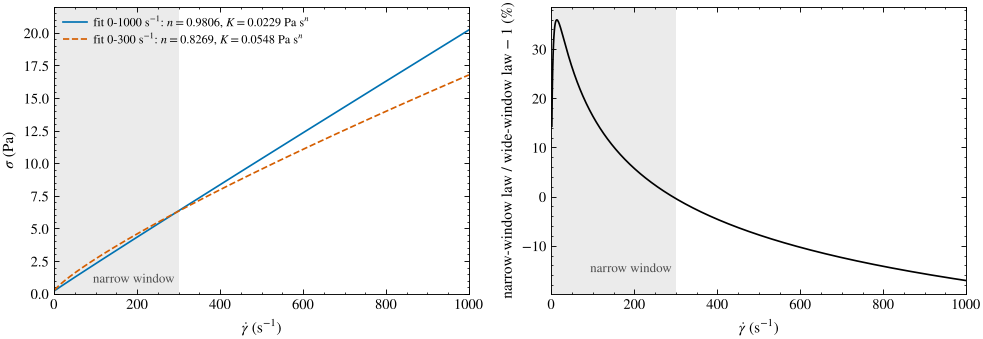

below 300 1/s the two laws are within 0.38 Pa of each other (at 100 1/s: 2.29 vs 2.67 Pa, +16 %); they cross near 292 1/s and differ by -17 % at 1000 1/s


In [16]:
atlas = pd.read_csv(DATA / "hb_parameter_atlas.csv")
fd3 = pd.read_csv(FIGDATA / "fig03_parameter_atlas.csv", comment="#")
win = atlas[atlas.source_key == "SaasenYtrehus2020"].set_index("material")
print(win[["sigma_y_Pa", "K_Pa_s_n", "n", "fit", "source_location"]].to_string(), "\n")
for mat, row in win.iterrows():
    f3 = fd3[fd3.material == mat].iloc[0]          # (the n column is text in this file: one row holds a range)
    assert np.isclose(float(f3.n), row.n) and np.isclose(float(f3.K_Pa_s_n), row.K_Pa_s_n) and np.isclose(float(f3.sigma_y_Pa), row.sigma_y_Pa)
n_wide, n_narrow = win.n.iloc[0], win.n.iloc[1]
assert round(n_wide, 2) == 0.98 and round(n_narrow, 2) == 0.83 and round(win.K_Pa_s_n.iloc[0], 3) == 0.023 and round(win.K_Pa_s_n.iloc[1], 3) == 0.055
print(f"Fig. 3 rows checked: n = {n_wide} (fit 0-1000 1/s) and {n_narrow} (fit 0-300 1/s); shift {n_wide - n_narrow:.2f}")

gd = np.linspace(1, 1000, 1000)
s_wide = hb_stress(gd, *win.iloc[0][["sigma_y_Pa", "K_Pa_s_n", "n"]].astype(float))
s_narrow = hb_stress(gd, *win.iloc[1][["sigma_y_Pa", "K_Pa_s_n", "n"]].astype(float))
rel = 100 * (s_narrow / s_wide - 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.3))
ax1.plot(gd, s_wide, color=C["blue"], label=rf"fit 0-1000 s$^{{-1}}$: $n={n_wide}$, $K={win.K_Pa_s_n.iloc[0]}$ Pa s$^n$")
ax1.plot(gd, s_narrow, color=C["red"], ls="--", label=rf"fit 0-300 s$^{{-1}}$: $n={n_narrow}$, $K={win.K_Pa_s_n.iloc[1]}$ Pa s$^n$")
ax1.axvspan(0, 300, color=C["lightgrey"], alpha=0.35, lw=0); ax1.text(290, 0.6, "narrow window", ha="right", va="bottom", fontsize=8.5, color="0.3")
ax1.set(xlabel=r"$\dot\gamma$ (s$^{-1}$)", ylabel=r"$\sigma$ (Pa)", xlim=(0, 1000), ylim=(0, 22)); ax1.legend(fontsize=8, loc="upper left")
ax2.plot(gd, rel, color=C["black"]); ax2.axvspan(0, 300, color=C["lightgrey"], alpha=0.35, lw=0)
ax2.text(290, -16, "narrow window", ha="right", va="bottom", fontsize=8.5, color="0.3")
ax2.set(xlabel=r"$\dot\gamma$ (s$^{-1}$)", ylabel="narrow-window law / wide-window law $-$ 1 (%)", xlim=(0, 1000))
fig.tight_layout(); plt.show()
in_win = gd <= 300
i100 = np.argmin(np.abs(gd - 100))
print(f"below 300 1/s the two laws are within {np.abs(s_narrow - s_wide)[in_win].max():.2f} Pa of each other "
      f"(at 100 1/s: {s_wide[i100]:.2f} vs {s_narrow[i100]:.2f} Pa, {rel[i100]:+.0f} %); they cross near "
      f"{gd[np.argmin(np.abs(rel[gd > 100])) + np.sum(gd <= 100)]:.0f} 1/s and differ by {rel[-1]:+.0f} % at 1000 1/s")

Below 300 s$^{-1}$ the two laws stay within 0.4 Pa of each other — small in absolute terms, although it is 16 % at 100 s$^{-1}$ (and up to 36 % near 13 s$^{-1}$), where the stresses are only 2–3 Pa or less — and they cross near the top of the narrow window; yet they differ in $n$ by 0.15 and in $K$ by a factor of 2.4, the trade-off along the valley of the HB fit (notebook 03). Above the narrow window they separate quickly, by 17 % at 1000 s$^{-1}$. Which set is "right" depends on what it is for: Saasen and Ytrehus found that the fit over the shear rates relevant to annular flow predicted the measured pressure loss better (Sec. VI D), and the review's lesson is to calibrate over the window of the application and to report that window with the parameters. On exact data from either law the three-rate diagnostic would return a constant exponent (0.98 or 0.83), so it cannot arbitrate between them either: with measurements this close to each other, only the window and its purpose can.

## 9. Try it yourself

**Exercise 1 — the Bingham and Newtonian limits.** Apply `triplet_parameters` to exact data from a Bingham plastic ($\sigma_y=5$ Pa, $\mu_p=0.2$ Pa s) and from a Newtonian liquid ($\mu=0.2$ Pa s) at rates 1, 4 and 16 s$^{-1}$. What does the diagnostic return, and what does it return for the Newtonian liquid with a 2 Pa torque offset added?

*Hint:* `hb_stress(rates, 5.0, 0.2, 1.0)` and `hb_stress(rates, 0.0, 0.2, 1.0) + 2.0`.

<details><summary>Solution</summary>

```python
rates = 1.0 * 4.0 ** np.arange(3)
print(triplet_parameters(1.0, 4.0, hb_stress(rates, 5.0, 0.2, 1.0)))         # (1.0, 0.2, 5.0)
print(triplet_parameters(1.0, 4.0, hb_stress(rates, 0.0, 0.2, 1.0) + 2.0))   # (1.0, 0.2, 2.0)
```
Both return $n=1$ and $K=0.2$ Pa s exactly. The Newtonian liquid with an offset is reported as a Bingham plastic with $\sigma_y=2$ Pa: the offset cannot be told from a yield stress by the diagnostic, which is the calibration caveat of Note S8.
</details>

**Exercise 2 — choosing the ratio.** For the worked-example law at $g=1$ s$^{-1}$ and $\varsigma_s=0.1$ Pa, evaluate the standard uncertainty of $n_{\rm tri}$ from Eq. (S23) for $r=1.5$, 2, 4, 10 and 100. How does it fall with $r$, and what is the price of a very large $r$?

*Hint:* `np.sqrt(var_ntri_S23(hb_stress(r ** np.arange(3), 10, 5, 0.5), r, 0.1))`.

<details><summary>Solution</summary>

```python
for r_ in [1.5, 2, 4, 10, 100]:
    print(r_, np.sqrt(var_ntri_S23(hb_stress(1.0 * r_ ** np.arange(3), 10, 5, 0.5), r_, 0.1)))
```
The uncertainty falls from about 0.5 at $r=1.5$ and 0.15 at $r=2$ to 0.027 at $r=4$, 0.007 at $r=10$ and 0.0007 at $r=100$: wider windows give larger increments and a larger $\ln r$ in the denominator. The price is resolution in rate — a window spanning four decades ($r=100$) averages over any crossover inside it (Sec. 4), and the top rate may leave the laminar, slip-free or steady regime.
</details>

**Exercise 3 — a crossover of your own.** Generate data from Eq. (13) with $n_0=0.3$, $\eta_s\dot\gamma_*/A=0.05$, add noise with $\varsigma_s=0.05$ Pa at $r=2$ (fixed seed), and plot $n_{\rm tri}$ with its error bars against $n_{\rm eff}$. Over which range of rates is the drift detectable, i.e. larger than the error bars?

*Hint:* reuse the cell of Sec. 5.3 with `stress_eq13` in place of `hb_stress`.

<details><summary>Solution</summary>

```python
eta_s = 0.05 * A / gstar
rates = 1e-3 * 2.0 ** np.arange(0, 24)
s_x = stress_eq13(rates, sy, A, gstar, 0.3, eta_s) + np.random.default_rng(3).normal(0, 0.05, rates.size)
gc, nt = sliding_triplets(rates, s_x, 2.0)
sd = np.array([np.sqrt(var_ntri_S23(s_x[i:i + 3], 2.0, 0.05)) for i in range(len(nt))])
plt.errorbar(gc, nt, sd, fmt="o"); plt.semilogx(gc, neff_eq14(gc, A, gstar, 0.3, eta_s)); plt.ylim(0, 1.2); plt.show()
```
Below about 1 s$^{-1}$ the increments are too small: several windows are rejected and the error bars are comparable with the distance to $n_0$. Between 1 and 5 s$^{-1}$ the departure from $n_0=0.3$ is only about 2σ (1.7–2.7 standard uncertainties); from about 8 s$^{-1}$ to the top of the range ($\approx4\times10^3$ s$^{-1}$) the rise toward 1 is several times its uncertainty (5.7σ at 8 s$^{-1}$, more than 10σ above 16 s$^{-1}$), and a single exponent is rejected. The drift says that the shape changes, not that a solvent is the reason (Note S8).
</details>

## Key points

* Three stresses at rates $g$, $rg$, $r^2g$ give $\Delta_2/\Delta_1=r^n$ for an HB branch (Eq. (S20)); the yield intercept cancels, so a constant offset leaves $n_{\rm tri}$ and $K_{\rm tri}$ unchanged and shifts only $\sigma_{y,\rm tri}$ — exponent consistency does not establish stress calibration.
* With independent stress errors, $\mathrm{Var}(n_{\rm tri})\simeq2\varsigma_s^2(\ln r)^{-2}(\Delta_1^{-2}+\Delta_2^{-2}+\Delta_1^{-1}\Delta_2^{-1})$ (Eq. (S23)); the increments are anticorrelated through the shared middle stress, the uncertainty blows up near a plateau, and adjacent windows are not independent.
* A drift of $n_{\rm tri}$ rejects a single exponent over the window but does not name the cause: a solvent crossover (Eq. (14), $n_{\rm eff}$ from $n_0$ to 1), an uncorrected instrument (the apparent wall curve of a capillary), slip or evolving structure all produce one.
* Fitted exponents are window-dependent even when the law is known: HB fits across a solvent crossover return any $n$ between $n_0$ and 1; the drilling fluid of Fig. 3 gave $n=0.98$ or 0.83 with $K$ differing by a factor 2.4, for laws that stay within 0.4 Pa of each other below 300 s$^{-1}$ and separate by 17 % at 1000 s$^{-1}$.
* Near onset the transport exponent is $1+1/n$ in pipes, channels and partly yielded Couette gaps and $p_s$ for a sliding plug (Table SIV), crossing over to $1/n$ only far above yield (Fig. 9(a)); a pressure–flow exponent is not the material's $1/n$.
* On the 1926 capillary data the diagnostic gives median exponents 0.82, 0.72 and 0.63 against the pooled fits 0.81, 0.74 and 0.68, with reconstructed yield stresses scattered around zero: compatible with a power law without yield stress, as Sec. II C concludes.

## References

The review and its repository:
* Y. Wang (2026). A century of the Herschel–Bulkley model (1926–2026): Widespread use, community achievements, predictive capability, and engineering implications. Manuscript submitted to the *Journal of Rheology*; code and data: https://github.com/ktwyw/hb-centenary-review

* Caggioni, M., Trappe, V., and Spicer, P. T. (2020). Variations of the Herschel–Bulkley exponent reflecting contributions of the viscous continuous phase to the shear rate-dependent stress of soft glassy materials. *Journal of Rheology* **64**, 413–422. https://doi.org/10.1122/1.5120633
* Herschel, W. H., and Bulkley, R. (1926). Konsistenzmessungen von Gummi-Benzollösungen. *Kolloid-Zeitschrift* **39**, 291–300. https://doi.org/10.1007/bf01432034
* Mooney, M. (1931). Explicit formulas for slip and fluidity. *Journal of Rheology* **2**, 210–222. https://doi.org/10.1122/1.2116364
* Mullineux, G. (2008). Non-linear least squares fitting of coefficients in the Herschel–Bulkley model. *Applied Mathematical Modelling* **32**, 2538–2551. https://doi.org/10.1016/j.apm.2007.09.010
* Rabinowitsch, B. (1929). Über die Viskosität und Elastizität von Solen. *Zeitschrift für Physikalische Chemie* **145A**, 1–26. https://doi.org/10.1515/zpch-1929-14502
* Saasen, A., and Ytrehus, J. D. (2020). Viscosity models for drilling fluids—Herschel–Bulkley parameters and their use. *Energies* **13**, 5271. https://doi.org/10.3390/en13205271

### Further reading

* Bonn, D., Denn, M. M., Berthier, L., Divoux, T., and Manneville, S. (2017). Yield stress materials in soft condensed matter. *Reviews of Modern Physics* **89**, 035005. https://doi.org/10.1103/revmodphys.89.035005
* Kelessidis, V. C., Maglione, R., Tsamantaki, C., and Aspirtakis, Y. (2006). Optimal determination of rheological parameters for Herschel–Bulkley drilling fluids and impact on pressure drop, velocity profiles and penetration rates during drilling. *Journal of Petroleum Science and Engineering* **53**, 203–224. https://doi.org/10.1016/j.petrol.2006.06.004
* Nelson, A. Z., and Ewoldt, R. H. (2017). Design of yield-stress fluids: a rheology-to-structure inverse problem. *Soft Matter* **13**, 7578–7594. https://doi.org/10.1039/C7SM00758B